# Access and modeled loneliness

## Goal

Reproduce the displayed results from distributed local inputs, without downloading data. Run every cell in order. Numerical statements are computed in the result cells; none are hard-coded.

## Setup

Use the project's Python environment. Start Jupyter inside this repository or set `ECONHACK_REPO` explicitly. The first cell runs `python -m econhack.cli verify` before reading data. The CLI checks source and processed manifests; tables and PNGs receive separate byte-hash receipts below. No acquisition functions or model `run()` entrypoints are called.

In [1]:
import hashlib
import importlib
import inspect
import io
import json
import os
from pathlib import Path
import subprocess
import sys

def find_repository():
    explicit = os.environ.get("ECONHACK_REPO")
    candidates = [Path(explicit).expanduser().resolve()] if explicit else [Path.cwd().resolve(), *Path.cwd().resolve().parents]
    for candidate in candidates:
        if (candidate / "src/econhack/cli.py").is_file() and (candidate / "pyproject.toml").is_file():
            return candidate
    raise FileNotFoundError("Open this notebook inside the repository, or set ECONHACK_REPO to its root.")

ROOT = find_repository()
os.environ["ECONHACK_OFFLINE"] = "1"
os.environ.setdefault("MPLCONFIGDIR", str(ROOT / ".cache/matplotlib"))
sys.path.insert(0, str(ROOT / "src"))
environment = os.environ.copy()
environment["PYTHONPATH"] = str(ROOT / "src") + os.pathsep + environment.get("PYTHONPATH", "")
verification = subprocess.run(
    [sys.executable, "-m", "econhack.cli", "verify"], cwd=ROOT, env=environment,
    capture_output=True, text=True, check=True,
)
print(verification.stdout.strip())
print(f"Repository: {ROOT.name}\nPython: {sys.version.split()[0]}\nMode: local files only")

import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import Code, Image, Markdown, display

pd.set_option("display.max_columns", 16)
pd.set_option("display.max_rows", 30)
pd.set_option("display.precision", 4)
plt.rcParams.update({"figure.figsize": (10, 5), "font.size": 11, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.prop_cycle": plt.cycler(color=["#176b87", "#b85c38"])})
PROCESSED = ROOT / "data/processed"
TABLES = ROOT / "outputs/tables"
FIGURES = ROOT / "outputs/figures"
input_receipts = []
processed_manifest = json.loads((ROOT / "data/processed_manifest.json").read_text())

def local_file(relative):
    path = (ROOT / relative).resolve()
    if ROOT not in path.parents or not path.is_file():
        raise FileNotFoundError(f"Required local input missing: {relative}. Run the project pipeline and snapshot first.")
    return path

def receipt(path):
    relative = str(path.relative_to(ROOT))
    input_receipts.append({"path": relative, "sha256": hashlib.sha256(path.read_bytes()).hexdigest()})

def read_csv(relative, **kwargs):
    path = local_file(relative)
    if str(path.relative_to(ROOT)).startswith("data/processed/") and str(path.relative_to(ROOT)) not in processed_manifest:
        raise ValueError(f"Processed input is not in the verified manifest: {relative}. Run cli snapshot first.")
    receipt(path)
    return pd.read_csv(path, **kwargs)

def read_json(relative):
    path = local_file(relative)
    receipt(path)
    return json.loads(path.read_text())

def show_png(name, required=True):
    path = FIGURES / f"{name}.png"
    if not path.is_file() and not required:
        display(Markdown(f"Figure `{name}.png` was not produced; consult the model status and estimability table."))
        return
    path = local_file(str(path.relative_to(ROOT)))
    receipt(path)
    display(Image(data=path.read_bytes(), format="png", embed=True, width=1000))

def show_figure(figure):
    buffer = io.BytesIO()
    figure.savefig(buffer, format="png", dpi=140, bbox_inches="tight")
    display(Image(data=buffer.getvalue(), format="png", embed=True, width=1000))

def show_source(module_name, names):
    module = importlib.import_module(module_name)
    display(Markdown(f"Source: `src/{module_name.replace('.', '/')}.py`. Functions below are displayed, not invoked."))
    for name in names:
        display(Code(inspect.getsource(getattr(module, name)), language="python"))

def show_status(name):
    statuses = read_json("outputs/model_status.json")
    display(pd.DataFrame([{key: value for key, value in statuses.get(name, {"status": "not_run"}).items()
                           if key in {"status", "reason", "n", "updated_utc", "formula", "input_mode"}}]))

Verified 38 source/extract hashes; 0 large source files omitted from distribution.
Repository: econhackathon2026
Python: 3.13.7
Mode: local files only


## Context and methods

Unit: NYC tract. CDC PLACES 2025 release provides modeled 2023 crude adult loneliness prevalence, joined by 11-digit tract GEOID to facility supply. The model is `loneliness_pct ~ log_access + log_income + poverty_pct + youth_pct + older_pct + log_density + C(borough)`, with HC3 covariance. The borough-only and adjusted models use the same complete-case sample. See `docs/models/loneliness.md`.

### Inspect the local analysis sample

In [2]:
sample = read_csv("data/processed/nyc_loneliness.csv", dtype={"geoid": str, "county": str})
assert not sample.geoid.duplicated().any()
assert sample.loneliness_pct.between(0, 100).all()
display(sample[["geoid", "borough", "year", "population", "nearby_800m", "loneliness_pct"]].head(12))
print(f"Complete-case tracts: {len(sample):,}; modeled outcome years: {sorted(sample.year.unique())}.")
show_status("access_loneliness")

,geoid,borough,year,population,nearby_800m,loneliness_pct
0,36005000200,Bronx,2023,5177,2,38.7
1,36005000400,Bronx,2023,6481,3,39.0
2,36005001600,Bronx,2023,6011,7,41.3
3,36005001901,Bronx,2023,2401,16,42.1
4,36005001902,Bronx,2023,1979,8,42.3
5,36005002001,Bronx,2023,4300,7,44.6
6,36005002002,Bronx,2023,3689,8,43.9
7,36005002300,Bronx,2023,4527,13,43.2
8,36005002500,Bronx,2023,5460,15,42.1
9,36005002701,Bronx,2023,2830,10,44.0


Complete-case tracts: 2,190; modeled outcome years: [np.int64(2023)].


,status,reason,updated_utc,n,formula
0,estimated_exploratory,2023 CDC modeled outcome vs current facilities...,2026-10-20T04:56:12.418772+00:00,2190,loneliness_pct ~ log_access + log_income + pov...


### Read exported estimates without refitting or hard-coded coefficients

In [3]:
coefficients = read_csv("outputs/tables/access_loneliness_coefficients.csv")
assert not coefficients.term.duplicated().any()
display(coefficients)
sensitivity = read_csv("outputs/tables/loneliness_adjustment_sensitivity.csv")
display(sensitivity)
estimate = coefficients.loc[coefficients.term.eq("log_access")].iloc[0]
print(f"Adjusted association: {estimate.coefficient:.3f} prevalence percentage points per unit of log1p(access); "
      f"95% HC3 interval [{estimate.ci_lower:.3f}, {estimate.ci_upper:.3f}].")

,term,coefficient,std_error,p_value,ci_lower,ci_upper
0,Intercept,79.2388,2.1717,1.8103e-291,74.9823,83.4953
1,C(borough)[T.Brooklyn],-1.7087,0.1405,4.9005e-34,-1.9841,-1.4334
2,C(borough)[T.Manhattan],1.3329,0.1687,2.7742e-15,1.0023,1.6636
3,C(borough)[T.Queens],1.0129,0.1542,5.0099e-11,0.7108,1.3150
4,C(borough)[T.Staten Island],-3.6615,0.2357,1.9507e-54,-4.1234,-3.1996
5,log_access,-0.1767,0.0971,6.8642e-02,-0.3669,0.0135
6,log_income,-3.5160,0.1582,1.8039e-109,-3.8260,-3.2060
7,poverty_pct,0.0257,0.0072,3.2804e-04,0.0117,0.0398
8,youth_pct,0.1542,0.0117,6.3090e-40,0.1313,0.1770
9,older_pct,-0.1089,0.0079,9.8147e-44,-0.1243,-0.0935


,model,coefficient_log_access,ci_lower,ci_upper,n
0,borough_only,1.2577,1.0268,1.4886,2190
1,adjusted,-0.1767,-0.3669,0.0135,2190


Adjusted association: -0.177 prevalence percentage points per unit of log1p(access); 95% HC3 interval [-0.367, 0.014].


### Recreate the descriptive scatter

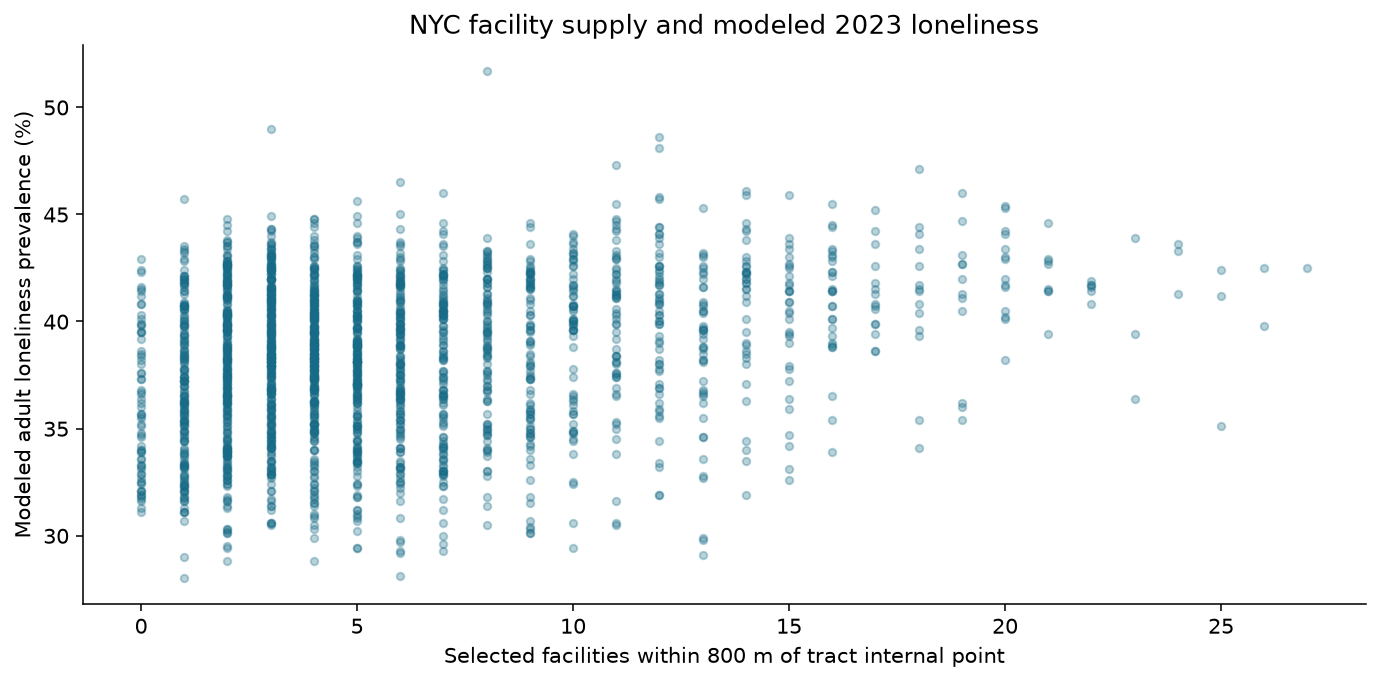

In [4]:
figure, axis = plt.subplots()
axis.scatter(sample.nearby_800m, sample.loneliness_pct, s=15, alpha=0.3)
axis.set(xlabel="Selected facilities within 800 m of tract internal point", ylabel="Modeled adult loneliness prevalence (%)",
         title="NYC facility supply and modeled 2023 loneliness")
figure.tight_layout()
show_figure(figure)
plt.close(figure)

### Saved charts and model diagnostics

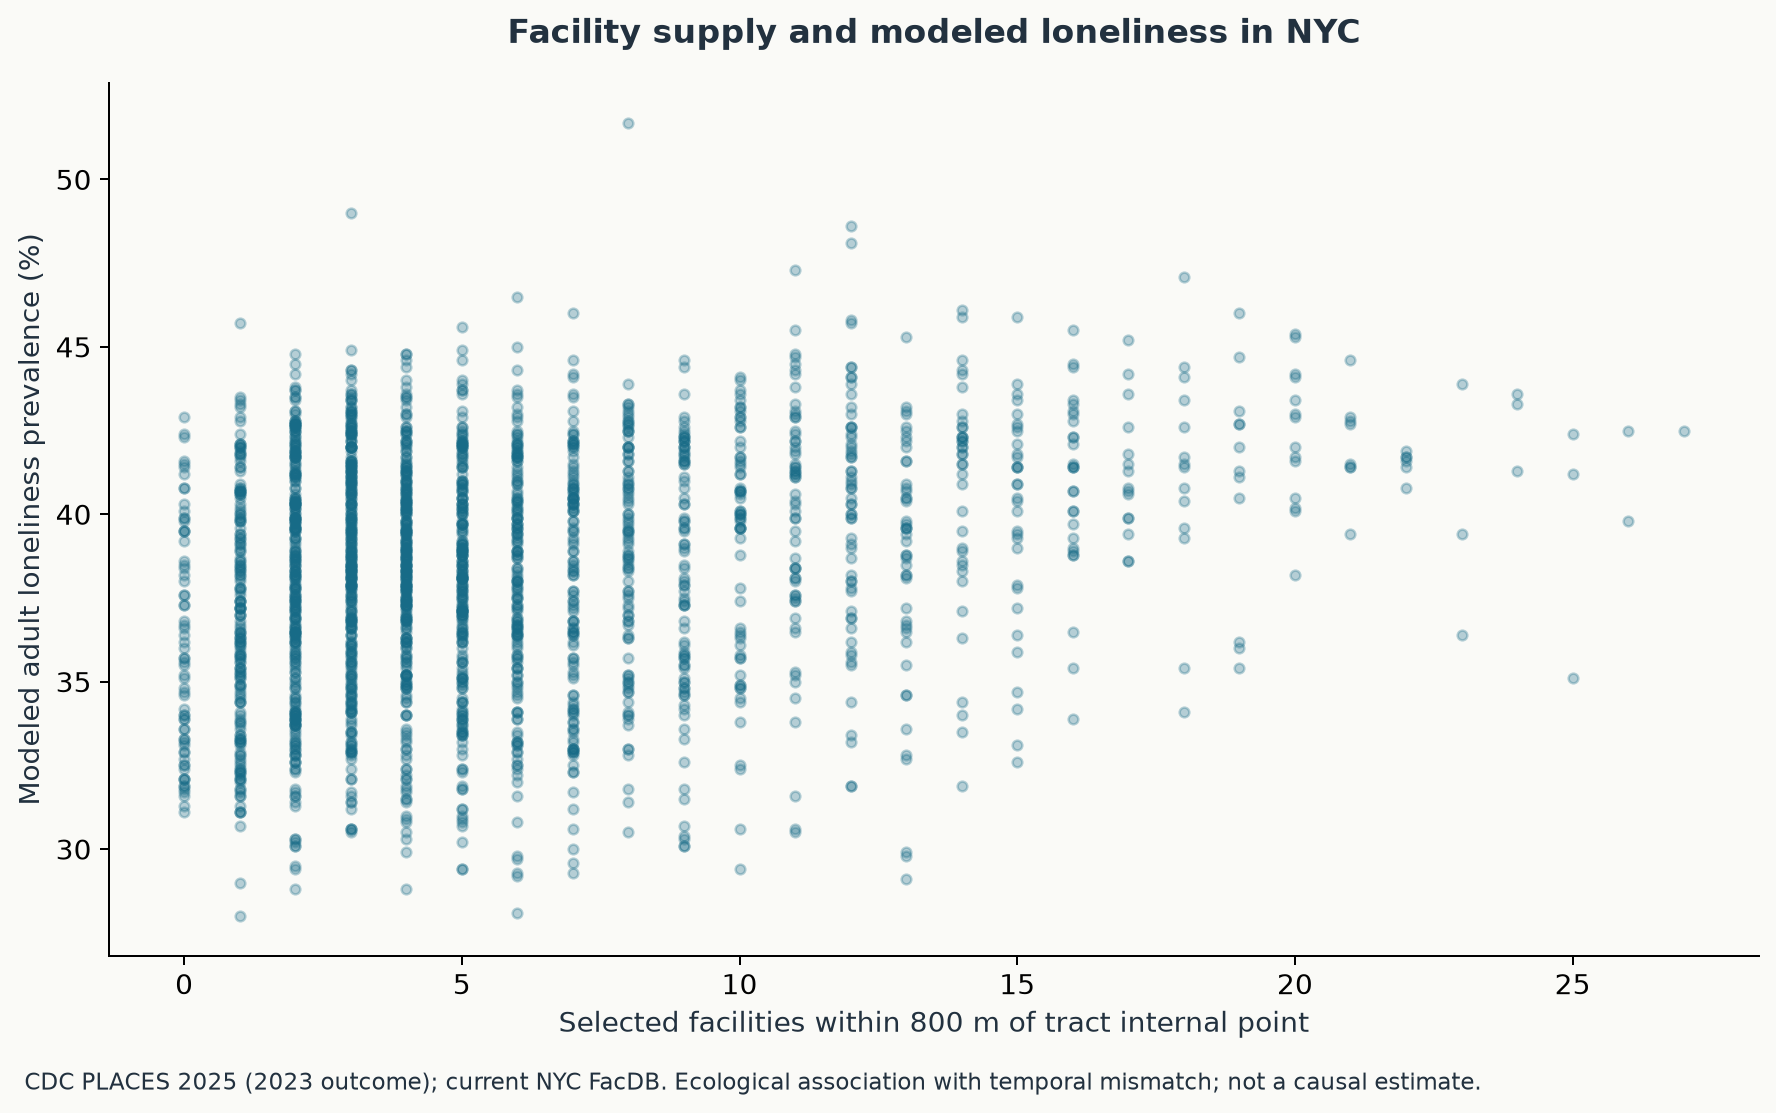

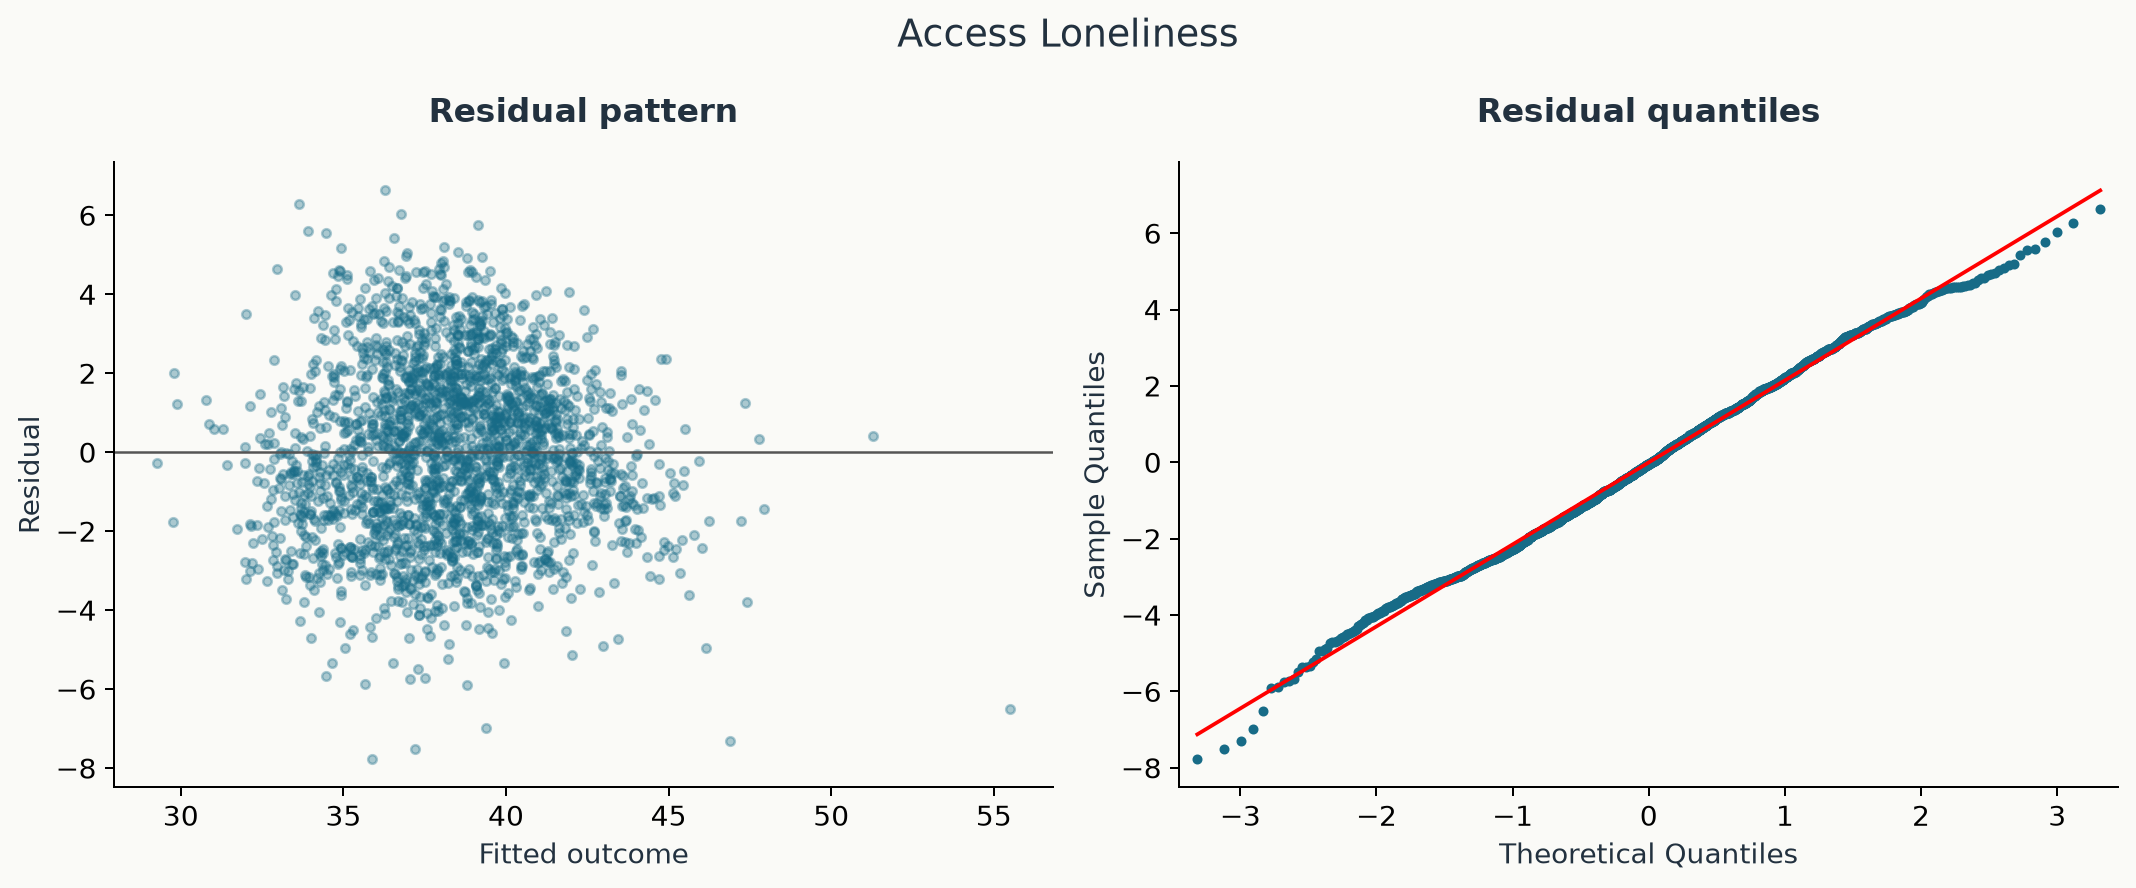

,n,r_squared,condition_number,covariance,design_rank,design_columns,breusch_pagan_p
0,2190,0.6333,1508.4651,HC3,11,11,2.3357e-31


,term,vif
0,Intercept,2347.6222
1,C(borough)[T.Brooklyn],2.3862
2,C(borough)[T.Manhattan],2.2315
3,C(borough)[T.Queens],2.6010
4,C(borough)[T.Staten Island],1.6653
5,log_access,1.9509
6,log_income,3.0955
7,poverty_pct,3.1604
8,youth_pct,1.1715
9,older_pct,1.3047


,variable,loneliness_pct,log_access,log_income,poverty_pct,youth_pct,older_pct,log_density
0,loneliness_pct,1.0000,0.2478,-0.5774,0.5232,0.4179,-0.3087,0.2176
1,log_access,0.2478,1.0000,-0.2696,0.4099,0.0764,-0.2227,0.5728
2,log_income,-0.5774,-0.2696,1.0000,-0.7778,-0.2028,0.0538,-0.1951
3,poverty_pct,0.5232,0.4099,-0.7778,1.0000,0.2534,-0.2105,0.2735
4,youth_pct,0.4179,0.0764,-0.2028,0.2534,1.0000,-0.3033,0.0564
5,older_pct,-0.3087,-0.2227,0.0538,-0.2105,-0.3033,1.0000,-0.2058
6,log_density,0.2176,0.5728,-0.1951,0.2735,0.0564,-0.2058,1.0000


,variable,loneliness_pct,log_access,log_income,poverty_pct,youth_pct,older_pct,log_density
0,loneliness_pct,12.5863,0.5942,-1.0154,21.4802,8.1380,-8.4010,0.5817
1,log_access,0.5942,0.4570,-0.0904,3.2072,0.2837,-1.1551,0.2917
2,log_income,-1.0154,-0.0904,0.2457,-4.4618,-0.5520,0.2044,-0.0728
3,poverty_pct,21.4802,3.2072,-4.4618,133.9381,16.1015,-18.6843,2.3847
4,youth_pct,8.1380,0.2837,-0.5520,16.1015,30.1354,-12.7736,0.2333
5,older_pct,-8.4010,-1.1551,0.2044,-18.6843,-12.7736,58.8450,-1.1895
6,log_density,0.5817,0.2917,-0.0728,2.3847,0.2333,-1.1895,0.5676


In [5]:
show_png("access_loneliness_scatter")
show_png("access_loneliness_diagnostics")
display(pd.DataFrame([read_json("outputs/qa/access_loneliness_diagnostics.json")]))
display(read_csv("outputs/tables/access_loneliness_vif.csv"))
display(read_csv("outputs/tables/access_loneliness_correlation.csv"))
display(read_csv("outputs/tables/access_loneliness_covariance.csv"))

### Inspect the actual model and adjustment comparison

In [6]:
show_source("econhack.nyc", ["loneliness"])

Source: `src/econhack/nyc.py`. Functions below are displayed, not invoked.

def loneliness(frame):
    query = urlencode({"$where": "stateabbr='NY' AND measureid='LONELINESS'", "$limit": 10000, "$order": "locationid"})
    path = fetch("https://data.cdc.gov/resource/cwsq-ngmh.json?" + query, "cdc/ny_loneliness_2025.json",
                 "CDC PLACES 2025 release, tract long format cwsq-ngmh, 2023 modeled loneliness", FEDERAL)
    source = pd.DataFrame(json.loads(path.read_text()))
    if len(source) >= 10000:
        raise ValueError("CDC query cap reached")
    if source.empty:
        record_status("access_loneliness", "incomplete", "No NY LONELINESS observations returned; no surrogate outcome fitted.")
        return
    required = {"measureid", "year", "data_value_type", "data_value", "locationid", "low_confidence_limit", "high_confidence_limit"}
    if not required.issubset(source.columns) or not source.measureid.eq("LONELINESS").all() or not source.year.astype(str).eq("2023").all():
        raise ValueError("CDC source schema, measure, or reference year changed")
    source = source[source.data_value_type.str.contains("Crude", case=False)].copy()
    source["geoid"] = source.locationid.astype(str).str.zfill(11)
    source["loneliness_pct"] = pd.to_numeric(source.data_value, errors="coerce")
    profile(source, "places_loneliness_ny", ["geoid"])
    if not source.loneliness_pct.dropna().between(0, 100).all():
        raise ValueError("Invalid CDC prevalence")
    for column in ["low_confidence_limit", "high_confidence_limit"]:
        source[column] = pd.to_numeric(source[column], errors="coerce")
    observed = source.dropna(subset=["loneliness_pct", "low_confidence_limit", "high_confidence_limit"])
    if not ((observed.low_confidence_limit <= observed.loneliness_pct) & (observed.loneliness_pct <= observed.high_confidence_limit) &
            observed.low_confidence_limit.ge(0) & observed.high_confidence_limit.le(100)).all():
        raise ValueError("Invalid CDC modeled confidence bounds")
    source.to_csv(PROCESSED / "cdc_ny_loneliness.csv", index=False)
    joined = frame.merge(source[["geoid", "loneliness_pct", "low_confidence_limit", "high_confidence_limit", "year"]], on="geoid", how="left", validate="one_to_one")
    predictors = ["log_access", "log_income", "poverty_pct", "youth_pct", "older_pct", "log_density"]
    sample = model_sample(joined, predictors + ["loneliness_pct"], "loneliness")
    sample.to_csv(PROCESSED / "nyc_loneliness.csv", index=False)
    formula = "loneliness_pct ~ log_access + log_income + poverty_pct + youth_pct + older_pct + log_density + C(borough)"
    result = smf.ols(formula, data=sample).fit(cov_type="HC3")
    regression_outputs(result, "access_loneliness", sample, ["loneliness_pct"] + predictors)
    spatial_sensitivity(sample, formula, "access_loneliness")
    unadjusted = smf.ols("loneliness_pct ~ log_access + C(borough)", data=sample).fit(cov_type="HC3")
    save_table(pd.DataFrame([{"model": label, "coefficient_log_access": fitted.params["log_access"],
                              "ci_lower": fitted.conf_int().loc["log_access", 0], "ci_upper": fitted.conf_int().loc["log_access", 1],
                              "n": fitted.nobs} for label, fitted in [("borough_only", unadjusted), ("adjusted", result)]]), "loneliness_adjustment_sensitivity")
    figure, axis = plt.subplots()
    axis.scatter(sample.nearby_800m, sample.loneliness_pct, alpha=.3, s=15)
    axis.set(xlabel="Selected facilities within 800 m of tract internal point", ylabel="Modeled adult loneliness prevalence (%)",
             title="Facility supply and modeled loneliness in NYC")
    figure.text(.02, -.02, "CDC PLACES 2025 (2023 outcome); current NYC FacDB. Ecological association with temporal mismatch; not a causal estimate.", fontsize=9)
    figure.tight_layout()
    save_figure(figure, "access_loneliness_scatter")
    record_status("access_loneliness", "estimated_exploratory", "2023 CDC modeled outcome vs current facilities; ACS shares overlap model inputs; temporal mismatch and eco

## Interpretation and limits

CDC values are modeled area estimates, not independent respondent observations. Demographic adjustments overlap inputs to the CDC model. Facility/outcome timing differs; HC3 does not propagate CDC or ACS uncertainty or handle spatial dependence. Neither a tract association nor a change after adjustment establishes an individual or causal effect.

## Inputs used

Exact local inputs and SHA-256 hashes for this execution. These receipts identify table/figure versions; they are not an independent validation of their statistical content.

In [7]:
display(pd.DataFrame(input_receipts).drop_duplicates().reset_index(drop=True))

,path,sha256
0,data/processed/nyc_loneliness.csv,6928c802abb6c832ac8bff646d3313261b7010d30831bc...
1,outputs/model_status.json,1c0591b04c884482be94eb86e682158fbfd08cc0a5f4fc...
2,outputs/tables/access_loneliness_coefficients.csv,80f323e241b3ee32a7f60aa76fb1f7000861c2b9fe9de6...
3,outputs/tables/loneliness_adjustment_sensitivi...,c07334171d16327660a1672130ef9b7f919f399e40b401...
4,outputs/figures/access_loneliness_scatter.png,cba6a022b19ac785e6d1120649e9010a7f25cd4ea769d2...
5,outputs/figures/access_loneliness_diagnostics.png,57ee482a3fcdab4b52c1f5032363af3cba663e2cb43491...
6,outputs/qa/access_loneliness_diagnostics.json,c00d8b420e6f50b9d768708684a491b2dadbd240b9804a...
7,outputs/tables/access_loneliness_vif.csv,4a5ed7ccfe0536ac10f7859e03f5d8a5d7ac8338088e0a...
8,outputs/tables/access_loneliness_correlation.csv,0bbe2b6b99f343654d3c2a815e691bbc440d984ae5b29f...
9,outputs/tables/access_loneliness_covariance.csv,1b0bdc88c7cfb6ed8c72392f9ca1b7226539c745e5315f...
